In [103]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [104]:
import sys
import warnings
warnings.simplefilter("ignore", UserWarning)

In [105]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
import matplotlib.colors as mcolors

In [106]:
sys.path.insert(0, '.')
sys.path.append("..")
sys.path.append("../src")

from plot_utils import (
    plot_loss_acc,
    plot_train_val_loss_acc_separately,
    plot_loss_acc_difference,
    plot_var_acc_legends,
    plot_similar_indices,
    plot_fid_vals,
    plot_cosine_similarity,
)

from utils import (
    concat_ckpt_metrics,
    top_last_influences,
    random_p_data,
    create_influences_dict,
    create_inf_int_distances,
    create_inter_entropies,
    create_inner_entropies,
    calc_pairwise_euclideans,
    calc_dist_inf_to_others,
    calc_volumes,
    pairwise_similarity,
    top_inf_indices,
    tsne_all_dataset,
    plt_decision_boundary,
    pw_cos_similarity,
    pw_fid,
)

from src.utils import load_checkpoint, train_func_classification

In [141]:
dir_tensors = os.path.join("../influences/dogfish", "dogfish_2025-05-17_00-36-01")
dir_tensors_no_hessian = os.path.join("../influences/dogfish", "dogfish_2025-05-19_23-38-04")
dir_tensors_tracin = os.path.join("../influences/dogfish", "dogfish_2025-05-28_23-05-16")
dir_ckpt = "../checkpoint/V3FC"
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.01
checkpoint_labels =  list([1, 2, 3, 5, 10, 15, 20, 40, 60, 80, 100])
epochs_range = range(1, num_epochs + 1)

In [142]:
class DogfishDataset(Dataset):
    def __init__(self, X, Y, transforms=None):
        self.X = X
        self.Y = Y
        self.transforms = transforms
        
    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        sample = self.X[idx]
        label = torch.tensor([self.Y[idx]])
        if self.transforms:
            sample = self.transforms(sample)
        return sample, label
    
DOGFISH_RAW_PATH = '../data/dogfish/dataset_dog-fish_train-900_test-300.npz'
DOGFISH_EMB_PATH = '../data/dogfish/dataset_dog-fish_embeds.npz'
embeds_data = np.load(DOGFISH_EMB_PATH, "r")
embeds_train_dataset = DogfishDataset(embeds_data["X_train"], embeds_data["Y_train"])
test_loader = DataLoader(DogfishDataset(embeds_data["X_test"], embeds_data["Y_test"]), batch_size=20, shuffle=False)

In [143]:
save_objs_dict_original = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)
save_objs_dict = torch.load(f"{dir_tensors_no_hessian}/accuracies_and_losses.pt", weights_only=False)
save_objs_dict_tracin = torch.load(f"{dir_tensors_tracin}/accuracies_and_losses.pt", weights_only=False)

save_objs_dict["influences_if"] = save_objs_dict_original["influences_if"]
save_objs_dict["influences_tracin"] = save_objs_dict_tracin["influences_tracin"]

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

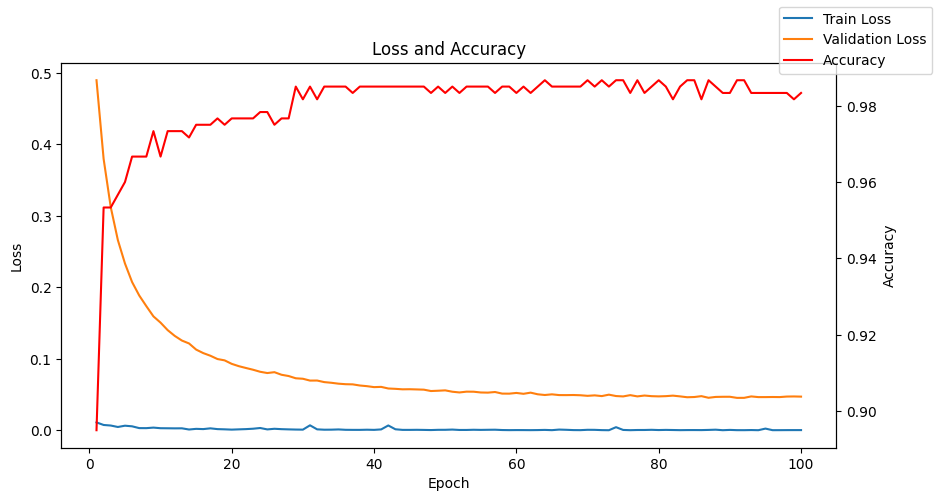

In [144]:
plot_loss_acc(epochs_range, train_losses, validation_losses, accuracies)

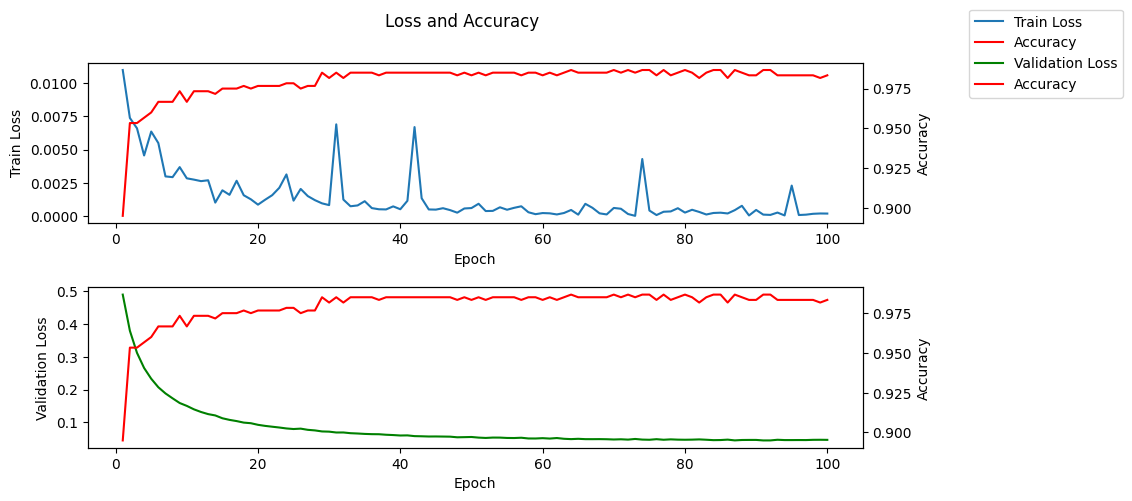

In [125]:
plot_train_val_loss_acc_separately(epochs_range, train_losses, validation_losses, accuracies)

# Influences

In [145]:
x_vals = list(range(1, num_epochs + 1))
num_data = len(embeds_train_dataset)
checkpoints_filepaths = [os.path.join(dir_ckpt, f"V3FC_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]
scoring_methods = ["if", "if_no_hessian", "tracin"]

dogfish_influence_if = save_objs_dict_original["influences_if"]
dogfish_no_hessian_if = save_objs_dict["influences_if_no_hessian"]
dogfish_influence_tracin = save_objs_dict_tracin["influences_tracin"]

save_objs_dict['validate_list_if'] = save_objs_dict_original["validate_list_if"]
save_objs_dict["rand_list_if"] = save_objs_dict_original["rand_list_if"]

save_objs_dict['validate_list_tracin'] = save_objs_dict_tracin["validate_list_tracin"]
save_objs_dict['rand_list_tracin'] = save_objs_dict_tracin["rand_list_tracin"]
# dogfish_influence_tracin = save_objs_dict["influences_tracin"]
validate_dict, rand_dict = create_influences_dict(save_objs_dict, checkpoint_labels, scoring_methods)

In [146]:
influences_methods = [dogfish_influence_if, dogfish_no_hessian_if, dogfish_influence_tracin]

p = 0.05

def generate_embed_dict(p):
    embeds_dict =  {}
    for i in range(len(scoring_methods)):
        the_random_embeds = random_p_data(influences_methods[i], embeds_train_dataset, num_data, p) 
        the_random_embeds_large = random_p_data(influences_methods[i], embeds_train_dataset, num_data, p*10)
        the_last_ckpts_embeds = top_last_influences(influences_methods[i], embeds_train_dataset, int(p*num_data), False) 
        the_top_ckpts_embeds = top_last_influences(influences_methods[i], embeds_train_dataset, int(num_data*p))

        embeds_dict[scoring_methods[i]] = {
            "random": the_random_embeds,
            "random_large": the_random_embeds_large, 
            "last": the_last_ckpts_embeds, 
            "top": the_top_ckpts_embeds}
    return embeds_dict
embeds_dict = generate_embed_dict(p)

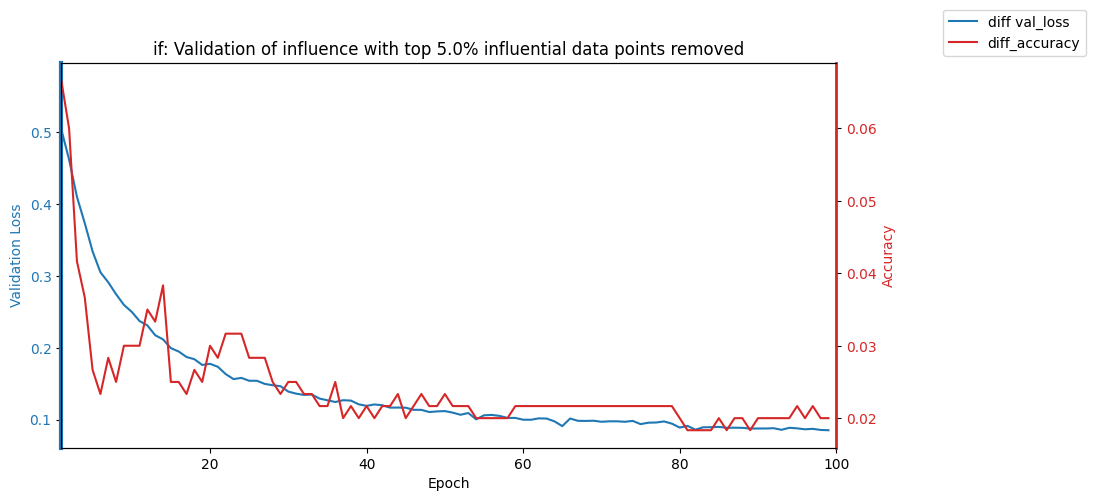

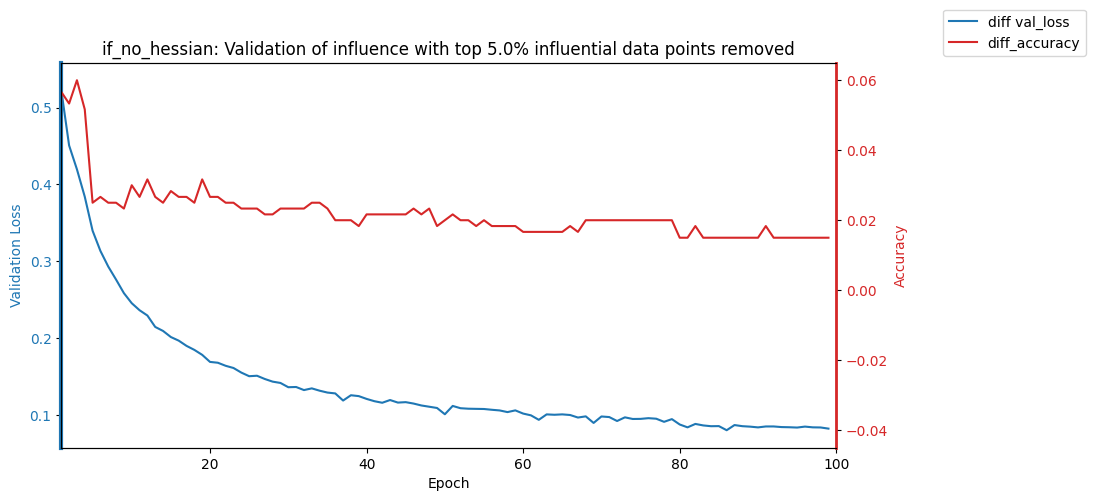

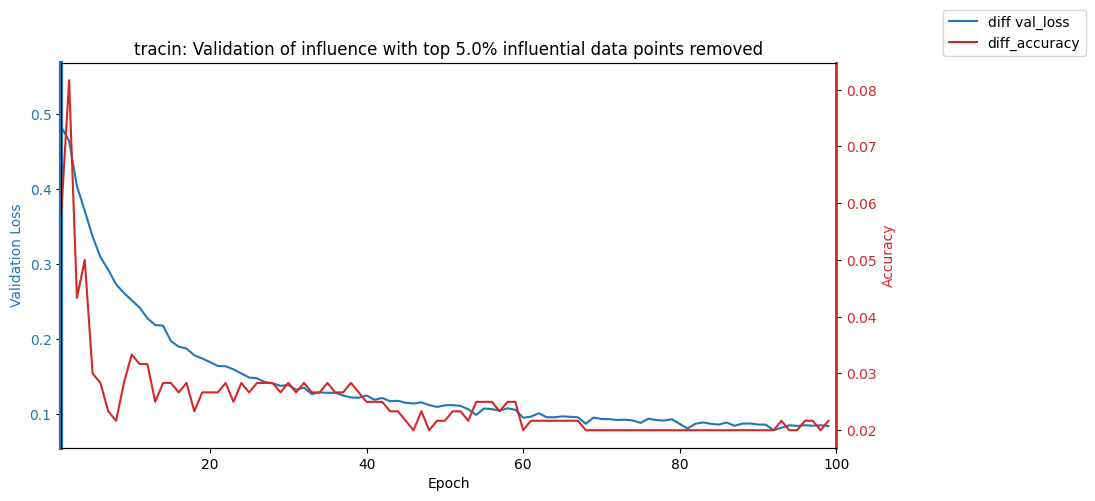

In [147]:
for scoring_method in scoring_methods:
    diff_val_loss = concat_ckpt_metrics(validate_dict[f"validate_validation_losses_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(rand_dict[f"rand_validate_train_losses_{scoring_method}"], checkpoint_labels) # suppose positive
    diff_accuracy = concat_ckpt_metrics(rand_dict[f"rand_validate_accuracies_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(validate_dict[f"validate_accuracies_{scoring_method}"], checkpoint_labels) # suppose positive
    plot_loss_acc_difference(diff_val_loss, diff_accuracy, scoring_method=f"{scoring_method}", p=p)

# Diversity

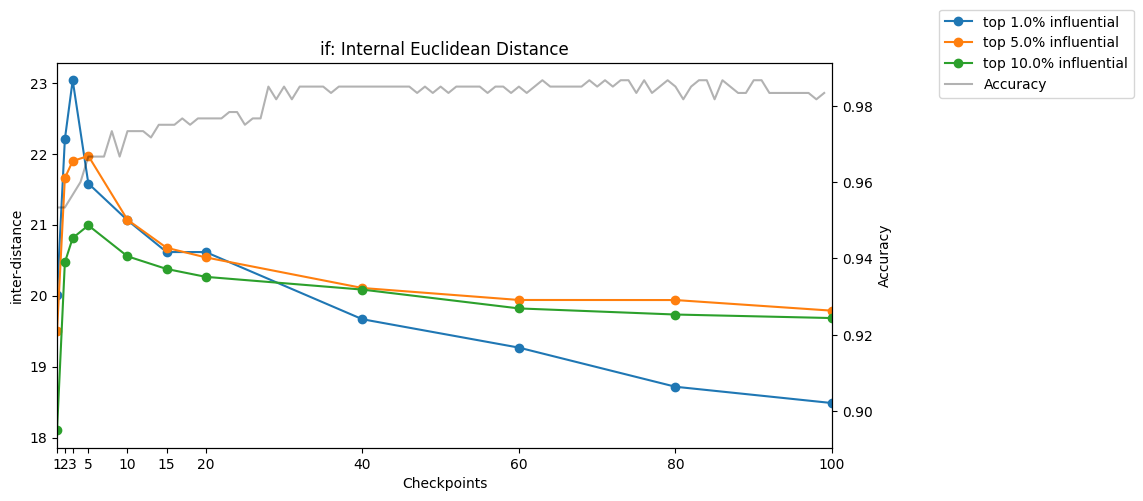

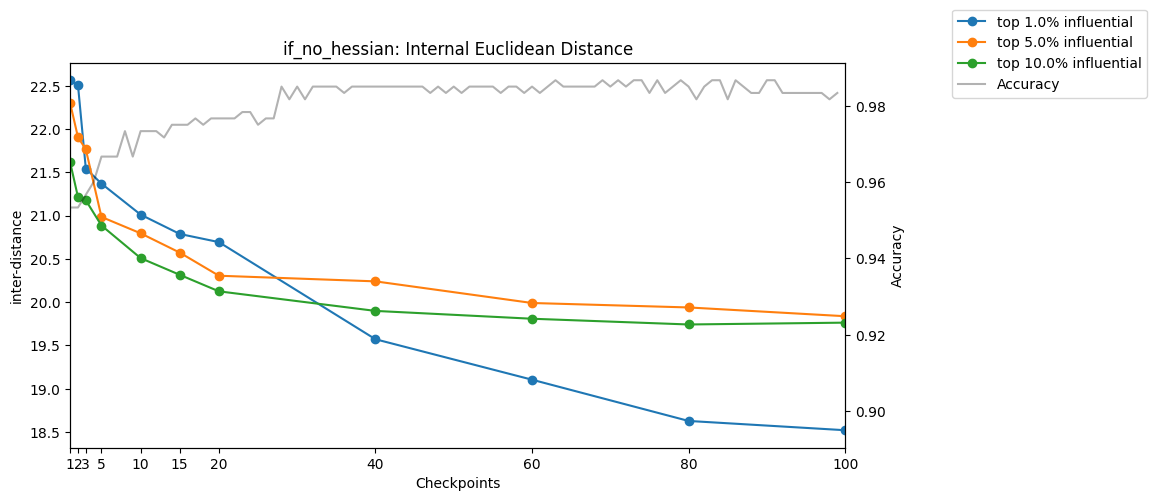

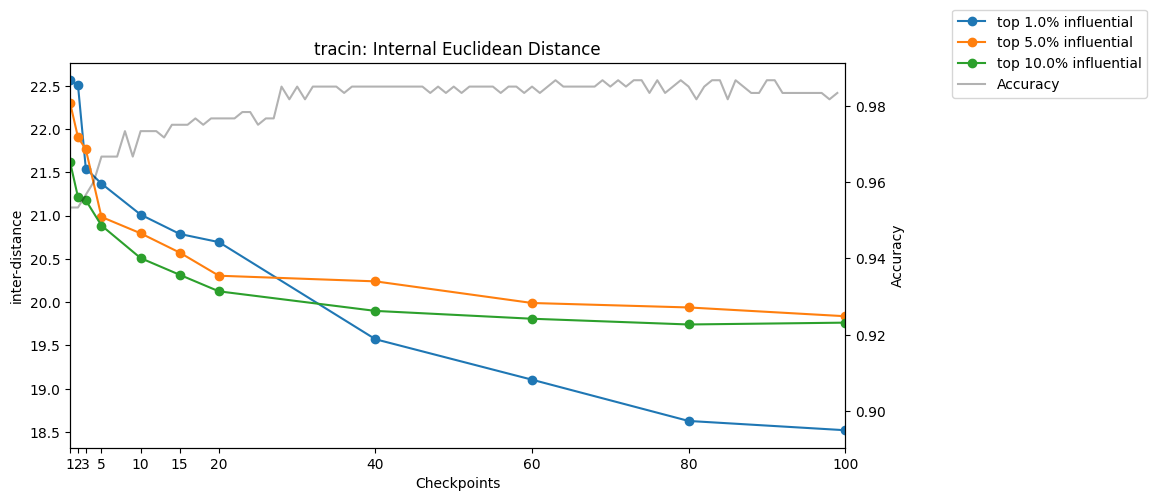

In [148]:
ls_p = [0.01, 0.05, 0.1]

for i in range(len(scoring_methods)):
    ls_int_distances = calc_pairwise_euclideans(influences_methods[i], embeds_train_dataset, ls_p, option='cv')
    kwargs = {
        "title": f"{scoring_methods[i]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": ls_int_distances,
        "legend_labels": [f"top {prob*100}% influential" for prob in ls_p]
    }
    
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

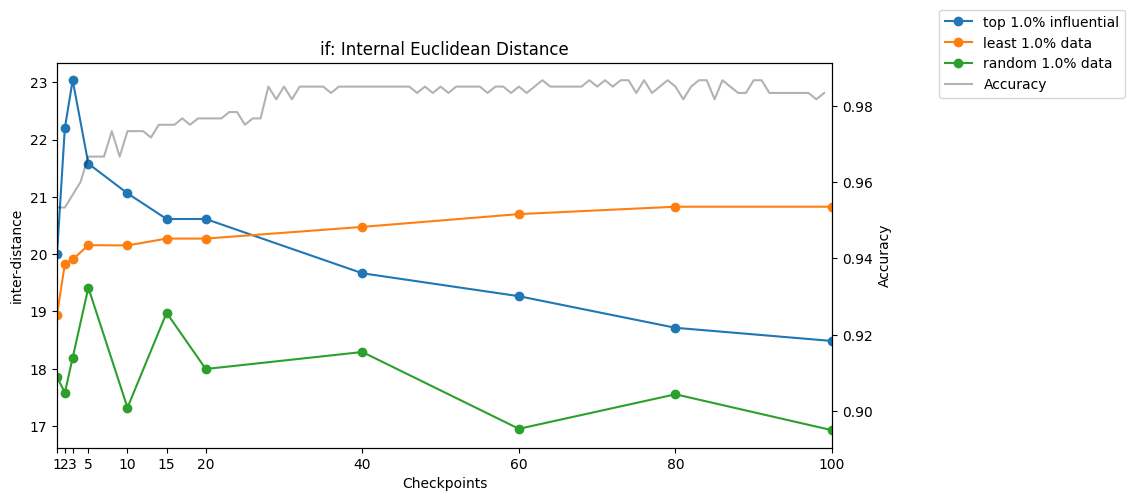

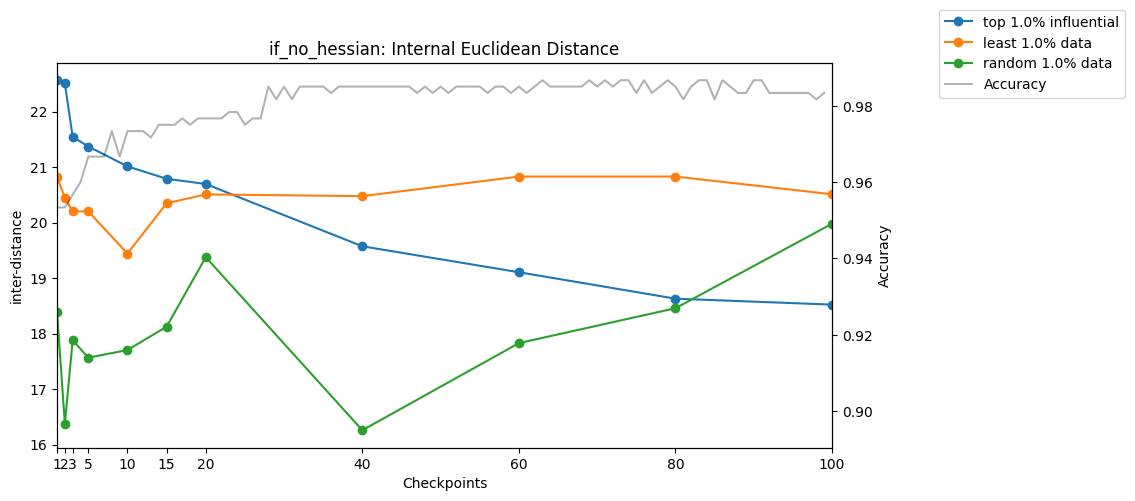

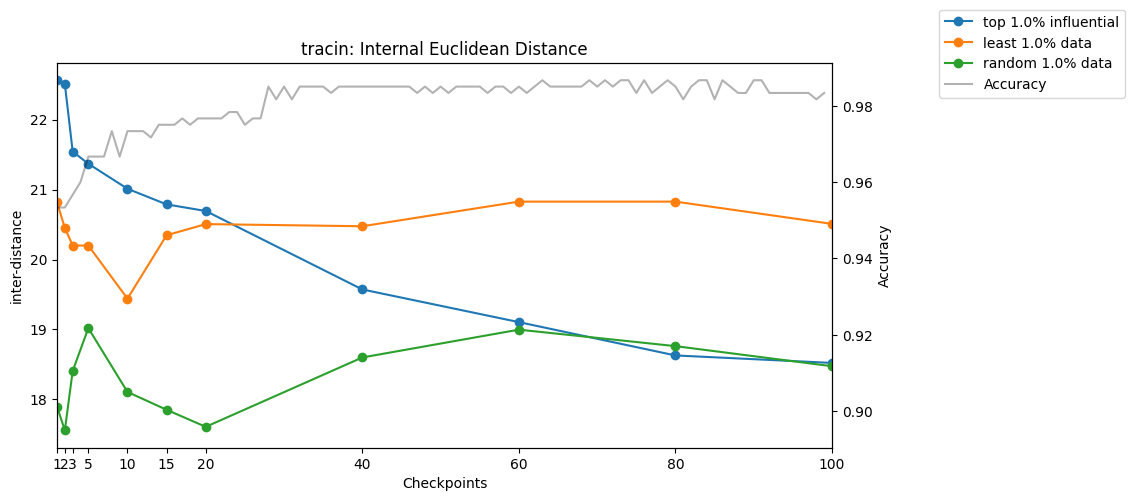

In [149]:
p = 0.01
embeds_dict = generate_embed_dict(p)
    
for i in range(len(scoring_methods)):
    topinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["top"])
    lastinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["last"])
    rand_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["random"])
    randlarge_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[i]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": [topinf_int_distances, lastinf_int_distances, rand_int_distances],
        "legend_labels": [f"top {p*100}% influential", f"least {p*100}% data", f"random {p*100}% data"],
        # "highlight_regions": [(0, 3), (3, 100)]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

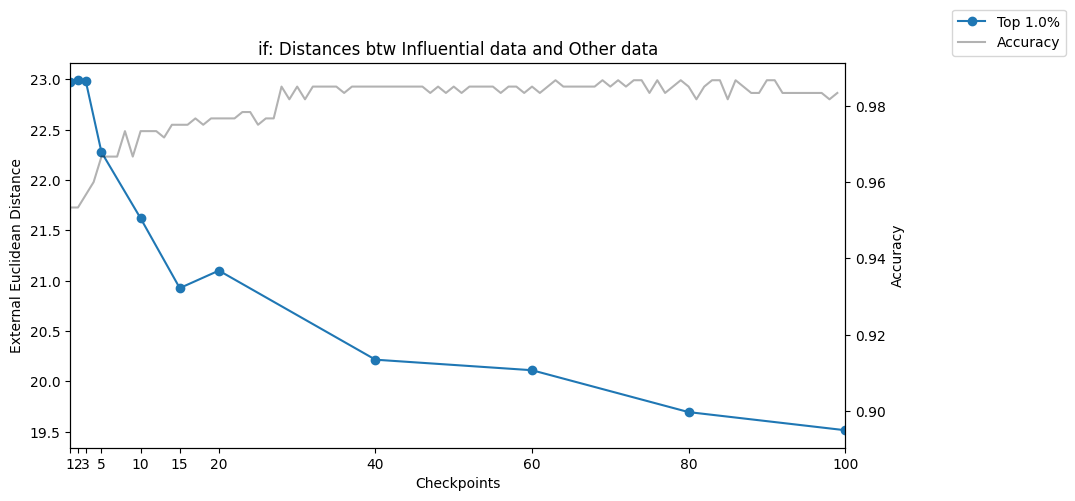

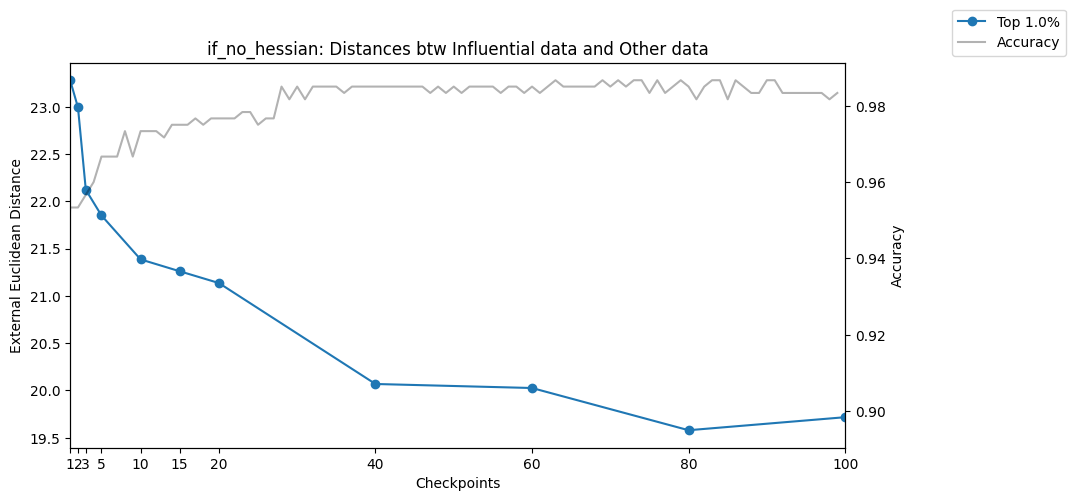

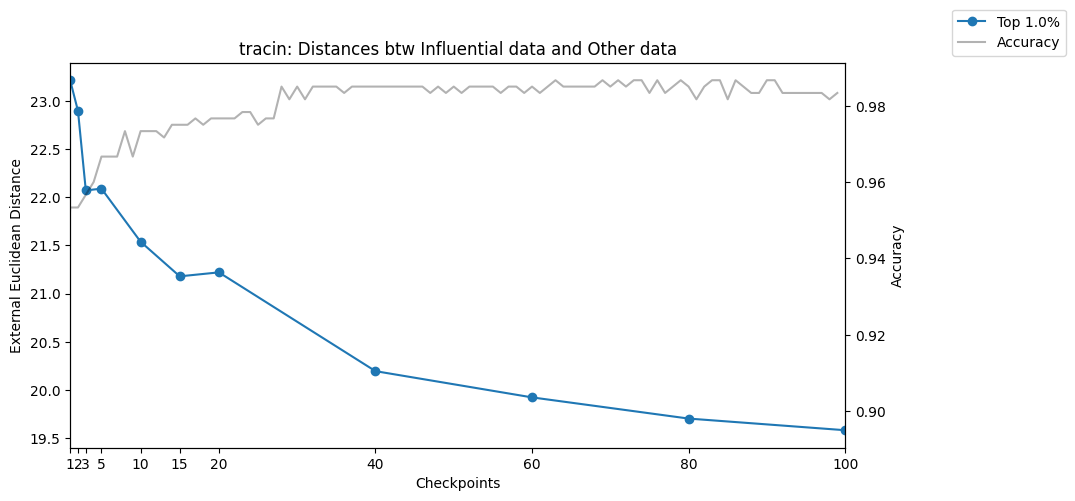

In [150]:
# Euclidean distance from influential points to other points
for i in range(len(scoring_methods)):
    topinf_distances = calc_dist_inf_to_others(select_inf_embeds = embeds_dict[scoring_methods[i]]["top"], 
                                        other_inf_embeds = embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[i]}: Distances btw Influential data and Other data",
        "y_label": "External Euclidean Distance",
        "data": [topinf_distances],
        "legend_labels": [f"Top {p*100}%"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

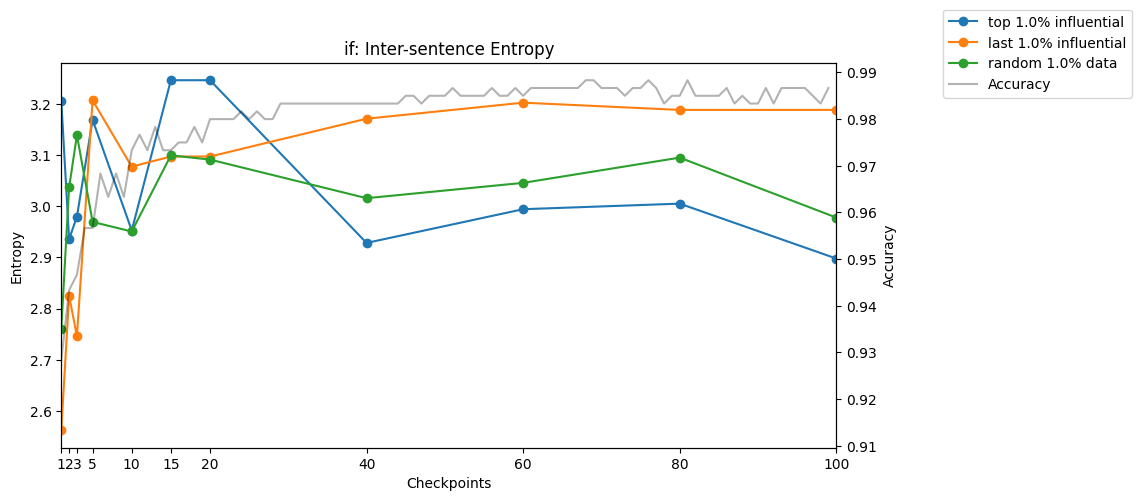

In [16]:
for i in range(len(scoring_methods)):
    topinf_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["top"])
    lastinf_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["last"])
    rand_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random"])
    # rand_pw_large_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random_large"])
    
    kwargs = {
        "title": f"{scoring_methods[i]}: Inter-sentence Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

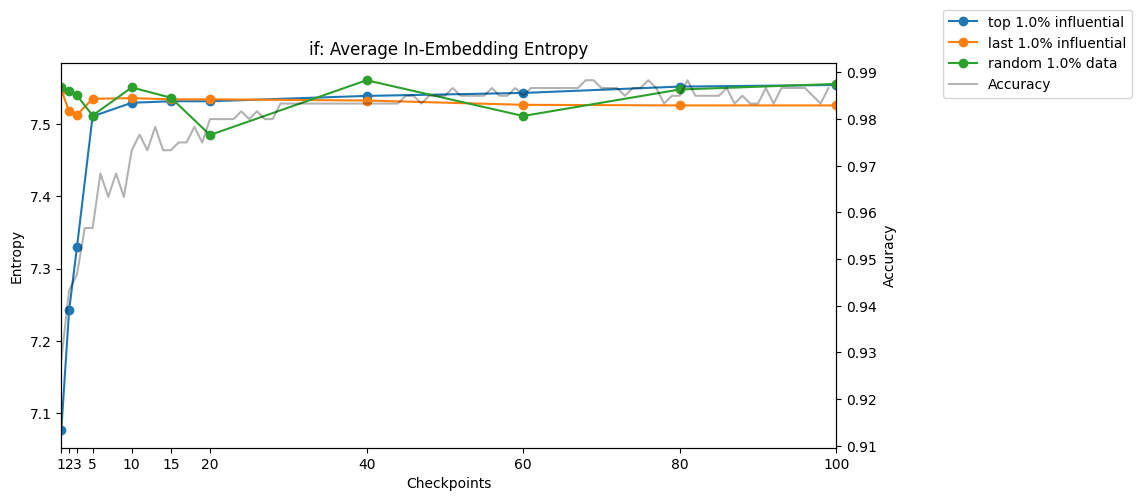

In [17]:
for i in range(len(scoring_methods)):
    topinf_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["top"])
    lastinf_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["last"])
    rand_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["random"])
    rand_pw_large_entropies = create_inner_entropies(embeds_dict[scoring_methods[i]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[i]}: Average In-Embedding Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

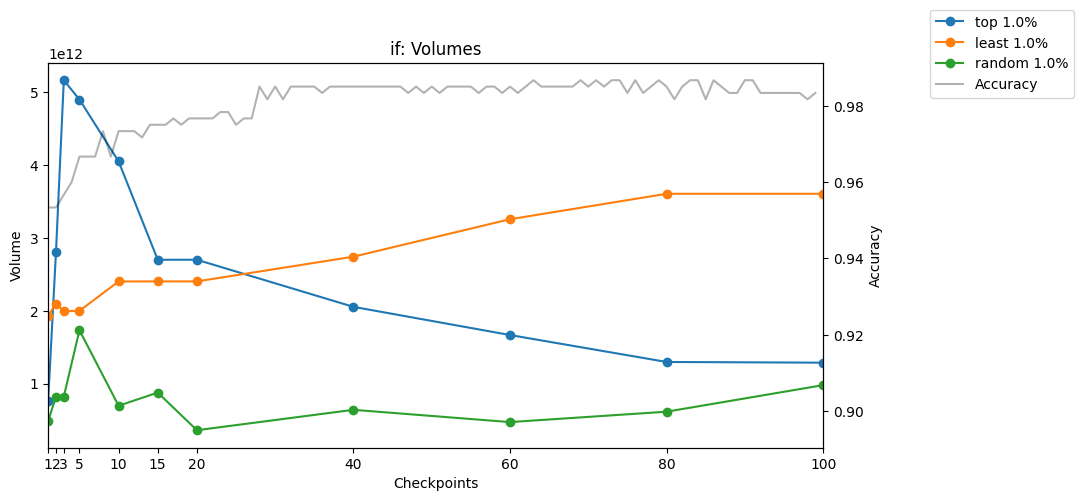

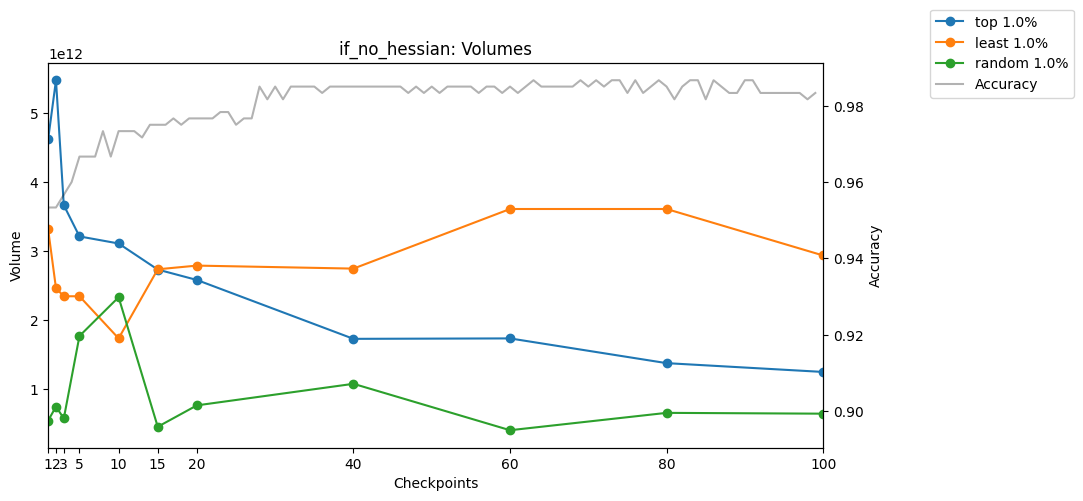

In [39]:
labels = ["top", "least", "random"]
    
for i in range(len(scoring_methods)):
    ls_volumes = calc_volumes([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]])
    kwargs = {
        "title": f"{scoring_methods[i]}: Volumes",
        "y_label": "Volume",
        "data": ls_volumes,
        "legend_labels": [f"{label} {p*100}%" for label in labels],
        # "highlight_regions": [(0, 3), (3, 100)]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

# Loss and Accuracy

In [40]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cpu


In [41]:
class V3FC(nn.Module):
    def __init__(self):
        super(V3FC, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(2048, 1),
            nn.Flatten(),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

In [42]:
def plot_get_losses(ls_embeds, legend_labels, losses):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))
    for j, ckpts_embeds in enumerate(ls_embeds):
        train_losses = [] # CrossEntropy loss
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(V3FC().parameters(), lr=0.0001)
            # print(f"Loading checkpoint {checkpoint}")
            model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
            loss_fn = nn.BCELoss()
            outputs = model(inputs).squeeze()
            loss = loss_fn(outputs, expect_val)
            train_losses.append(loss.item())
            
        ax1.plot(checkpoint_labels, train_losses, 'o-', 
                label=f"{legend_labels[j]} {p*100}% train loss")

    plt.title("Train loss (BCE)")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Loss")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(losses, label="train loss", color='k', alpha=0.4)

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

def plot_get_accs(ls_embeds, legend_labels, train_accuracies):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))

    for j, ckpts_embeds in enumerate(ls_embeds):
        accuracies = []
        
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(V3FC().parameters(), lr=0.0001)
            model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            predictions = (outputs > 0.5).int()
            accuracy = (predictions == expect_val).sum() / len(expect_val)
            accuracies.append(accuracy.cpu())
            
        ax1.plot(checkpoint_labels, accuracies, 'o-', 
                label=f"{legend_labels[j]} {p*100}% accuracy")

    plt.title("Training data accuracy")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(train_accuracies, label="Accuracy", color='k', alpha=0.4)

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

## For IF

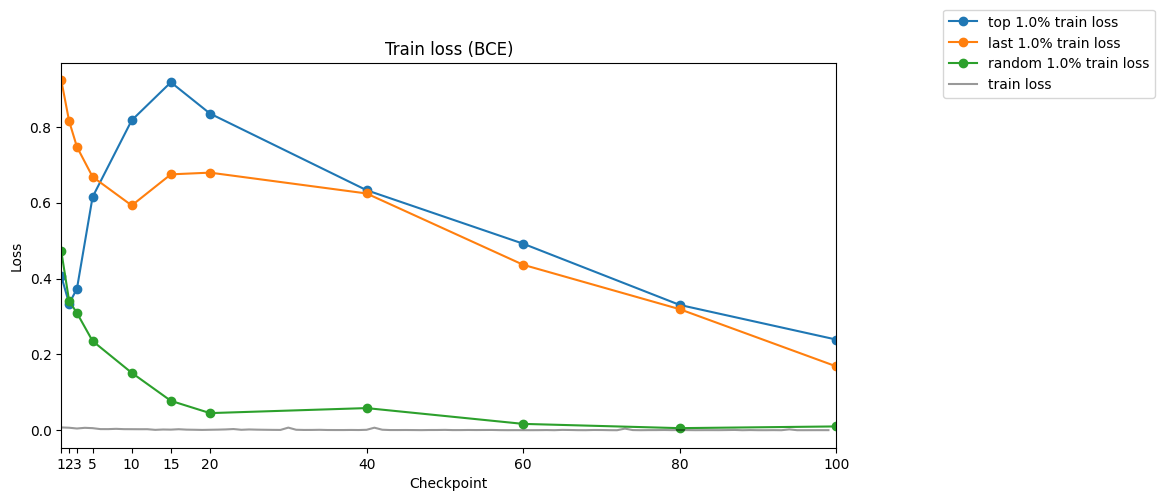

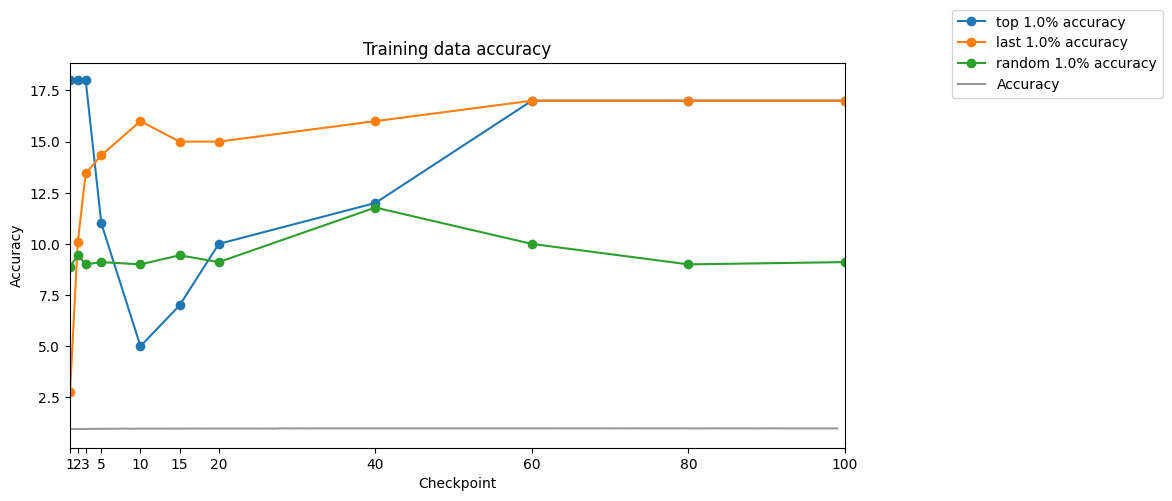

In [43]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["if"]["top"],
             embeds_dict["if"]["last"],
             embeds_dict["if"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

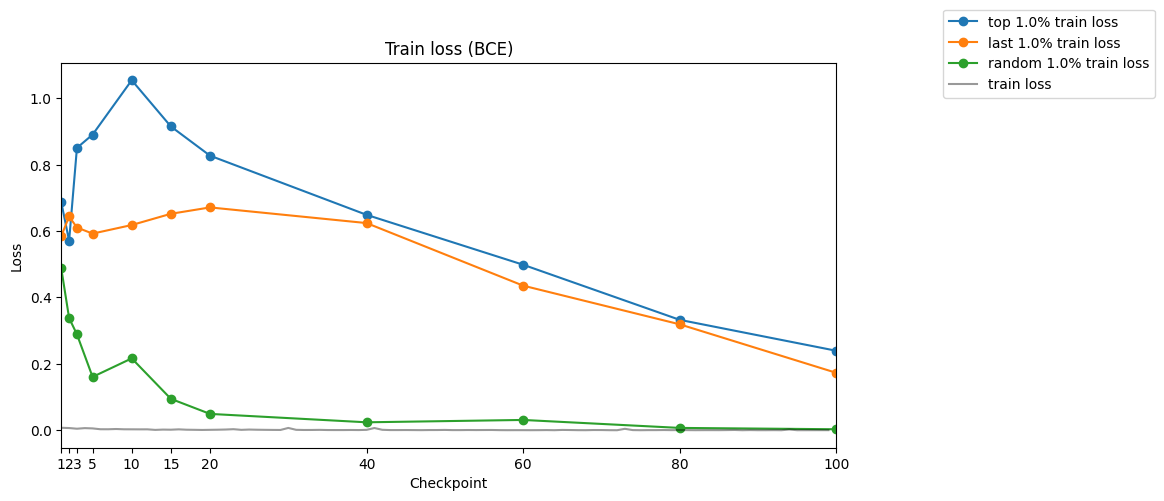

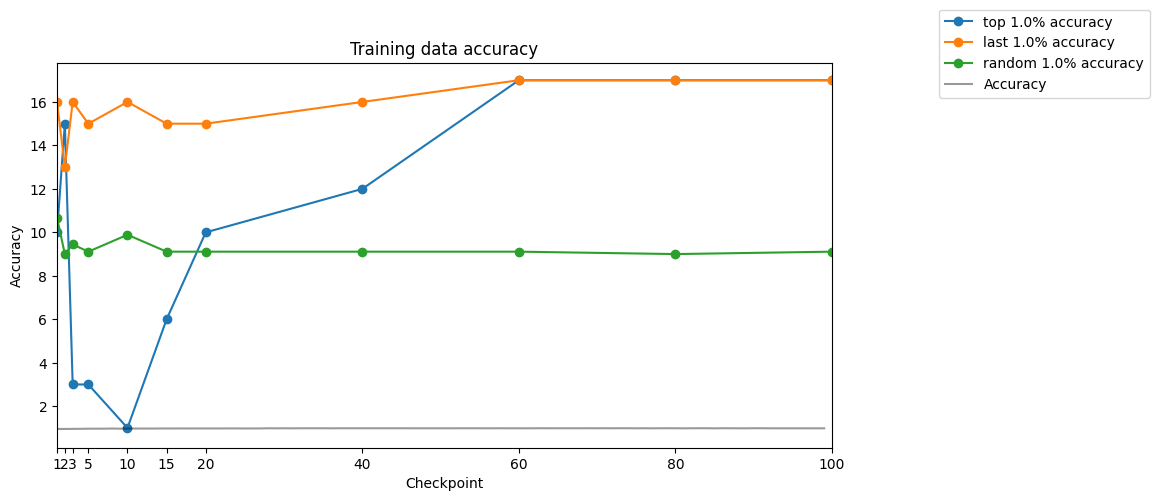

In [20]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["if_no_hessian"]["top"],
             embeds_dict["if_no_hessian"]["last"],
             embeds_dict["if_no_hessian"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

## For TracIn

In [23]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["tracin"]["top"],
             embeds_dict["tracin"]["last"],
             embeds_dict["tracin"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

KeyError: 'tracin'

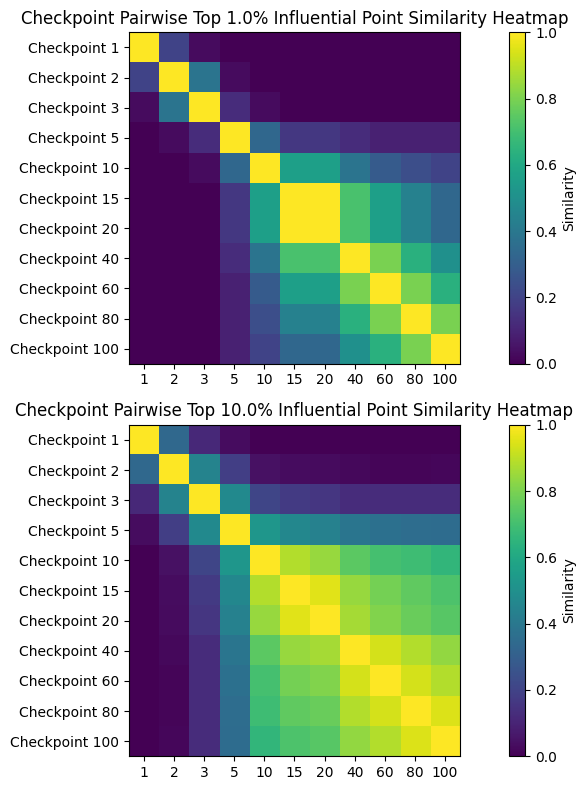

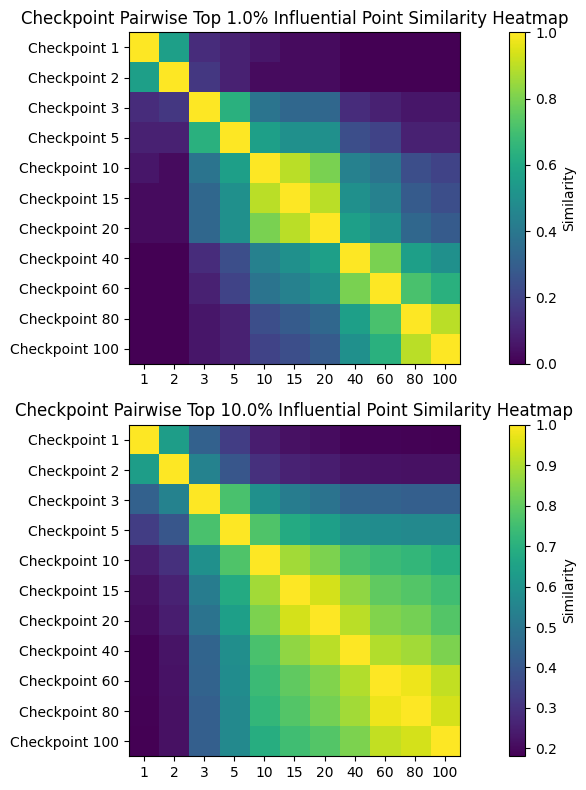

In [44]:
for i in range(len(scoring_methods)):
    pw_similarities_lowp = pairwise_similarity(top_inf_indices(influences_methods[i], int(p*num_data)))
    pw_similarities_highp = pairwise_similarity(top_inf_indices(influences_methods[i], int(0.1*num_data)))

    plot_similar_indices(pw_similarities_lowp, checkpoint_labels, p, pw_similarities_highp)

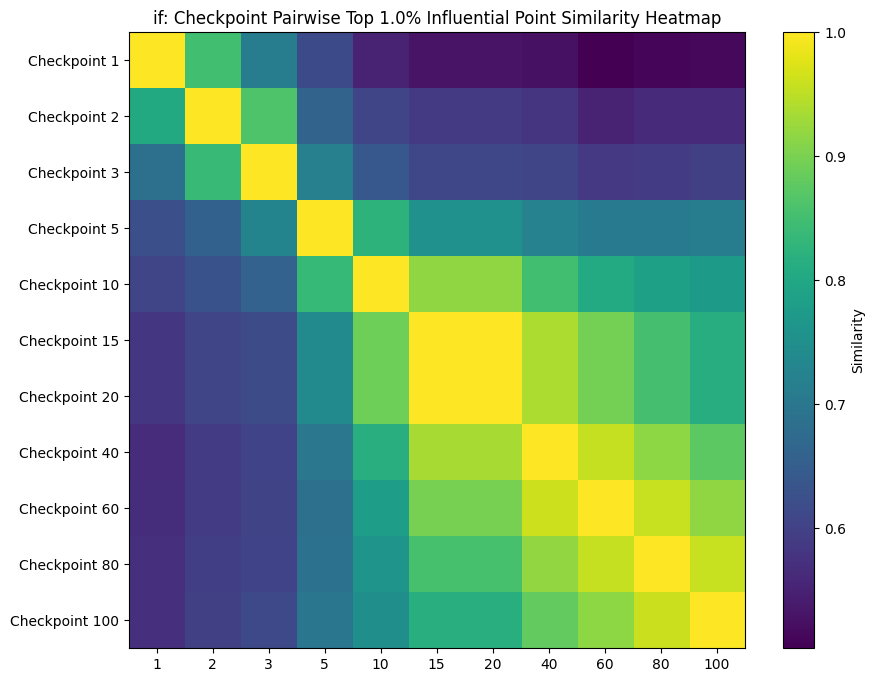

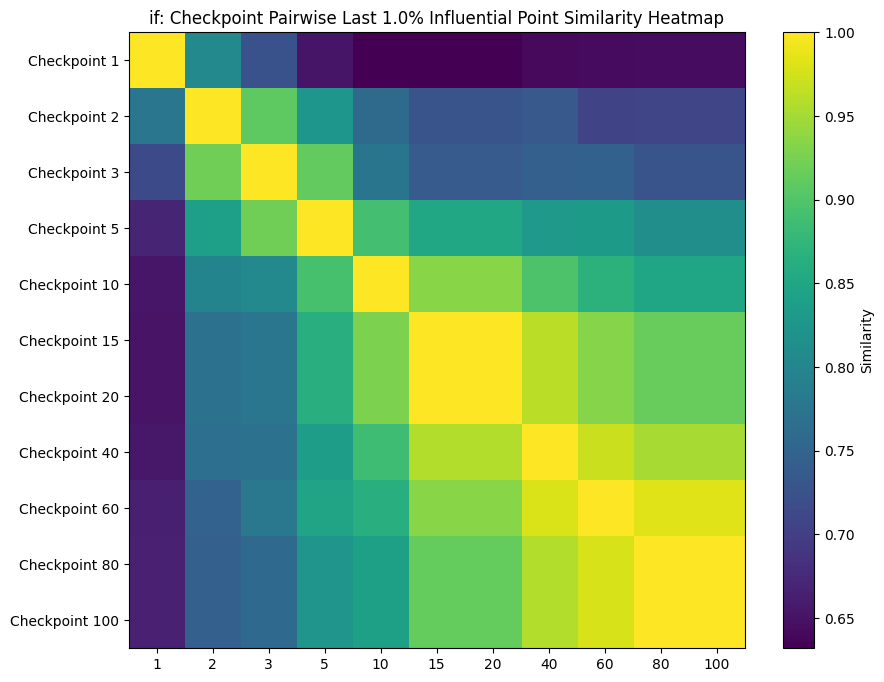

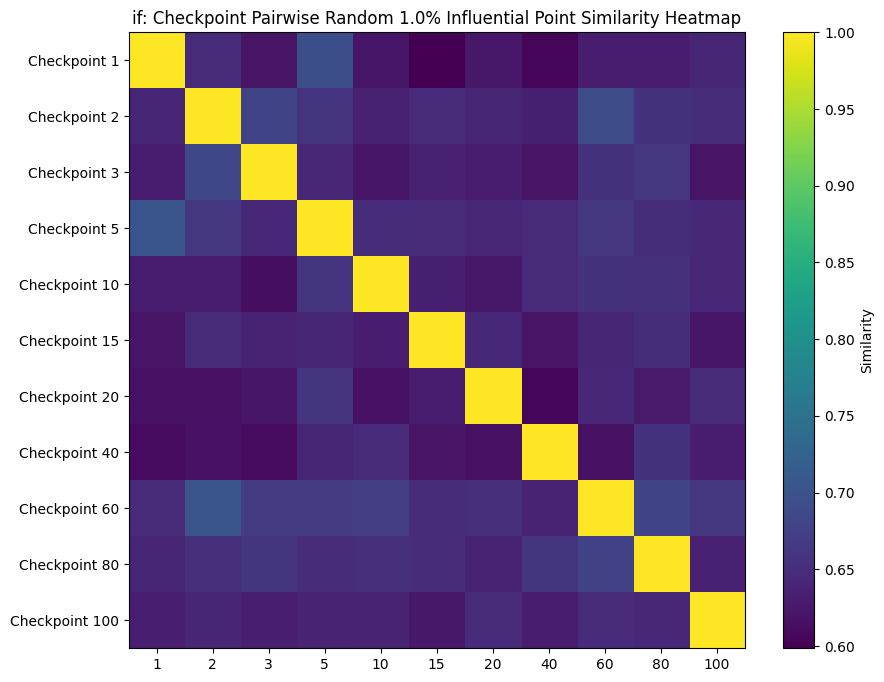

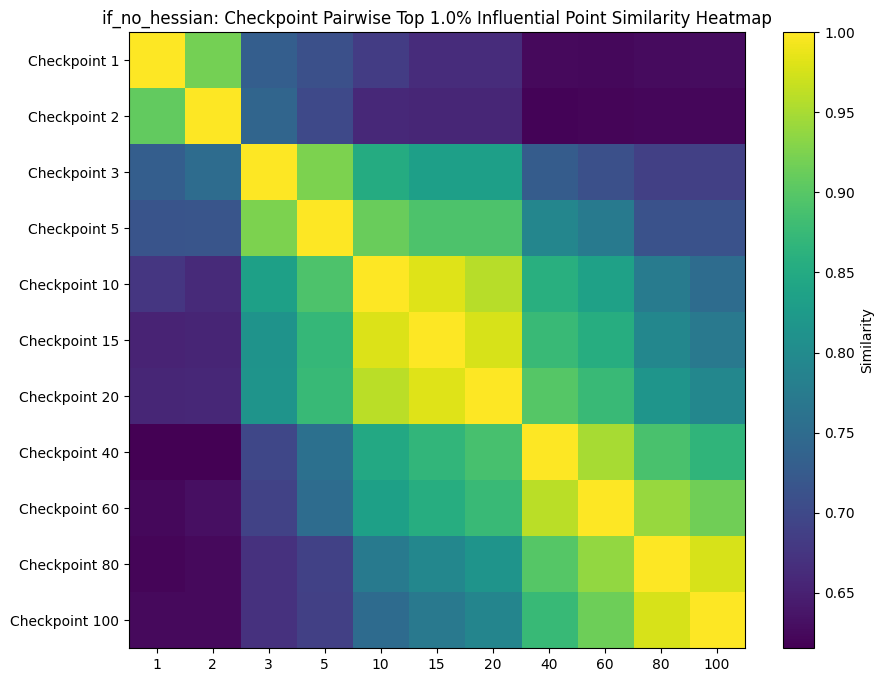

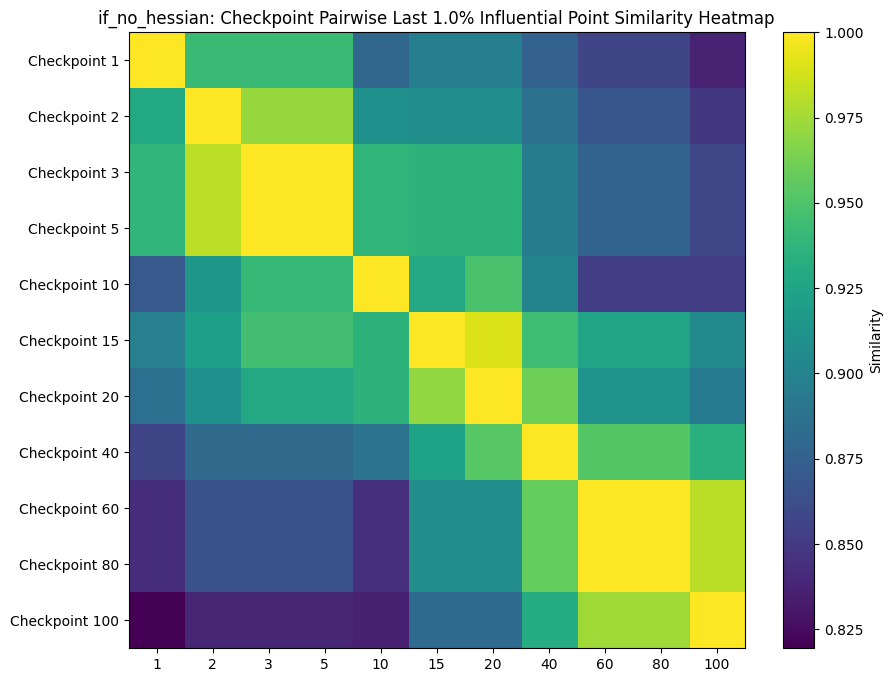

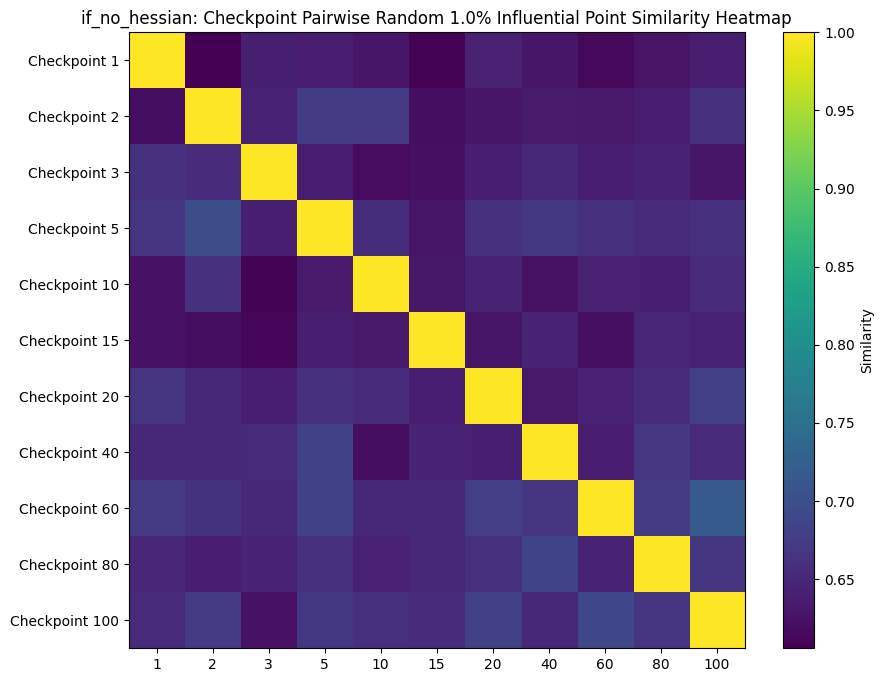

In [57]:
p = 0.01
embeds_dict = generate_embed_dict(p)
for k in range(len(scoring_methods)):
    topinf_cos = pw_cos_similarity(embeds_dict[scoring_methods[k]]["top"])
    lastinf_cos = pw_cos_similarity(embeds_dict[scoring_methods[k]]["last"])
    rand_cos = pw_cos_similarity(embeds_dict[scoring_methods[k]]["random"])
    plot_cosine_similarity(topinf_cos, checkpoint_labels, p, scoring_methods[k])
    plot_cosine_similarity(lastinf_cos, checkpoint_labels, p, scoring_methods[k], kind="Last")
    plot_cosine_similarity(rand_cos, checkpoint_labels, p, scoring_methods[k], kind="Random")

# Decision Boundary

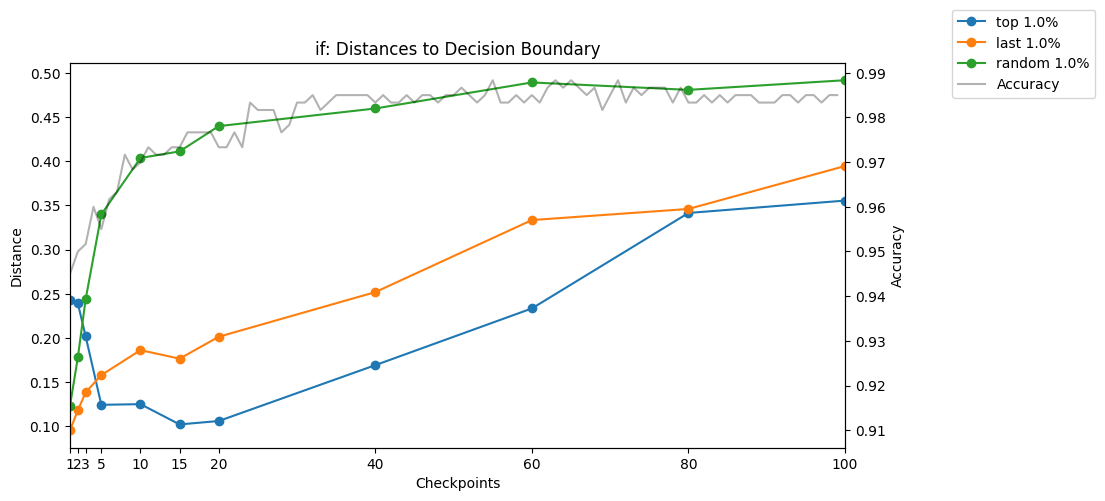

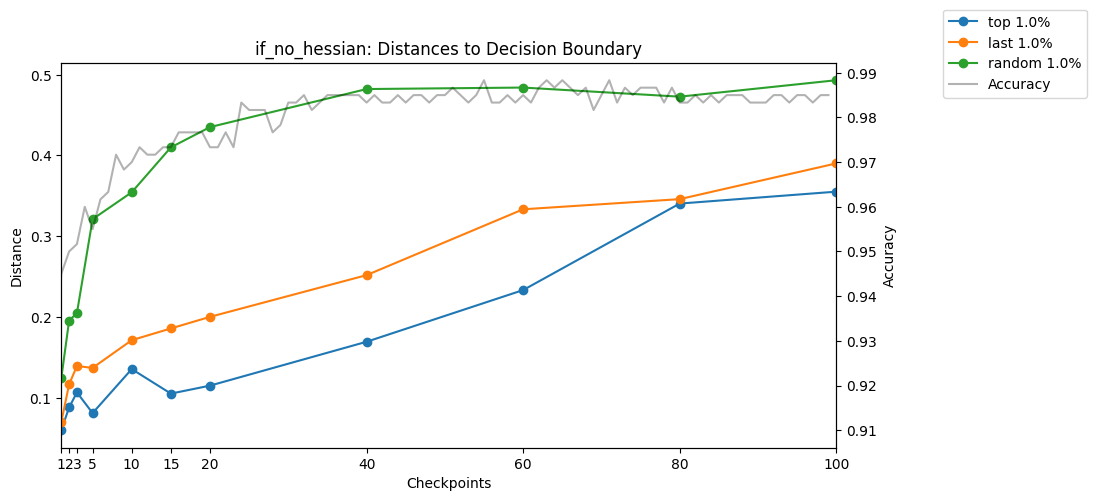

In [98]:
p = 0.01
optimizer = torch.optim.Adam(V3FC().parameters(), lr=0.0001)
for i in range(len(scoring_methods)):
    dist_lst = []
    for j, ckpts_embeds in enumerate([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]]):
        disappear_dist = []
        for k, embeds in enumerate(ckpts_embeds):    
            checkpoint = checkpoints_filepaths[k]
            inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
            model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            topinf_distances = torch.mean(torch.abs(outputs - 0.5))
            disappear_dist.append(topinf_distances.item())
        dist_lst.append(disappear_dist)
    
    kwargs = {
        "title": f"{scoring_methods[i]}: Distances to Decision Boundary",
        "y_label": "Distance",
        "data": dist_lst,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

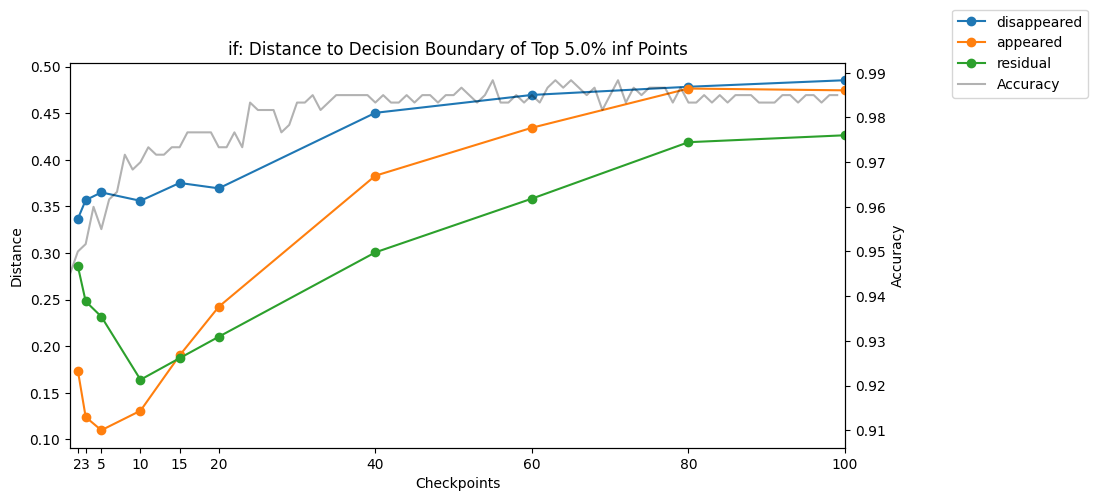

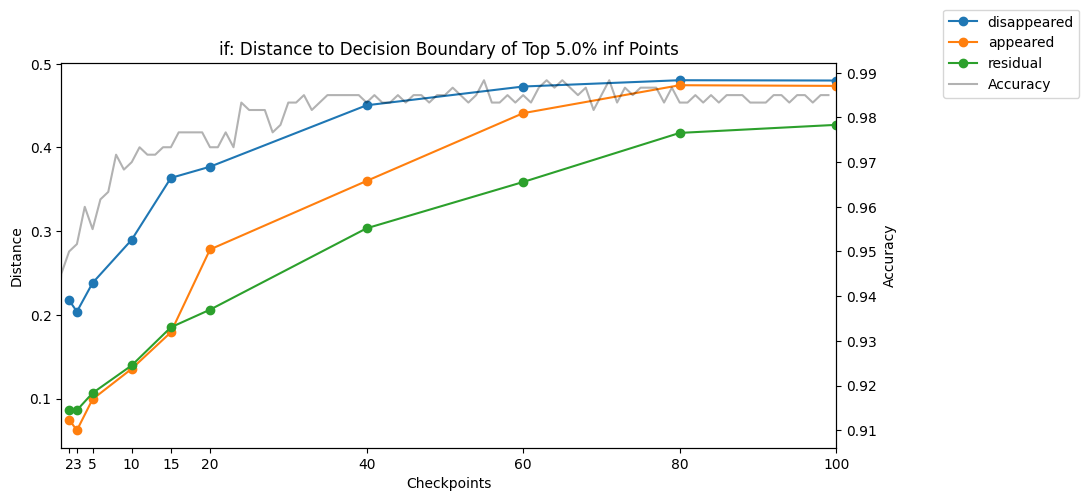

In [105]:
p = 0.05
def generate_dist_to_decision_boundary(model, dataset):
    outputs = torch.tensor([model(torch.tensor(data[0]).unsqueeze(0)) for data in dataset])
    distance_to_dec_boundary = torch.mean(torch.abs(outputs - 0.5))
    return distance_to_dec_boundary

for i in range(len(influences_methods)):
    topinf_indexes = top_inf_indices(influences_methods[i], int(p*num_data))
    disappeared_distances = []
    appeared_distances = []
    residual_distances = []

    for i in range(1, len(topinf_indexes)):
        checkpoint = checkpoints_filepaths[i]
        optimizer = torch.optim.Adam(V3FC().parameters(), lr=1e-4)
        model, _, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        
        disappear_topinf_indices = set(topinf_indexes[i-1]).difference(set(topinf_indexes[i]))
        disappear_subset = Subset(embeds_train_dataset, list(disappear_topinf_indices))
        disappear_dist = generate_dist_to_decision_boundary(model, disappear_subset)
        disappeared_distances.append(disappear_dist)
        
        newly_appeared_indices = set(topinf_indexes[i]).difference(topinf_indexes[i-1])
        appeared_subset = Subset(embeds_train_dataset, list(newly_appeared_indices))
        appeared_dist = generate_dist_to_decision_boundary(model, appeared_subset)
        appeared_distances.append(appeared_dist)
        
        residual_indices = set(topinf_indexes[i]).intersection(topinf_indexes[i-1])
        residual_subset = Subset(embeds_train_dataset, list(residual_indices))
        residual_dist = generate_dist_to_decision_boundary(model, residual_subset)
        residual_distances.append(residual_dist)

    kwargs = {
        "data": [disappeared_distances, appeared_distances, residual_distances],
        "title": f"if: Distance to Decision Boundary of Top {p*100}% inf Points",
        "y_label": "Distance",
        "legend_labels": ["disappeared", "appeared", "residual"]
    }

    plot_var_acc_legends(x_vals, checkpoint_labels[1:], accuracies, **kwargs)


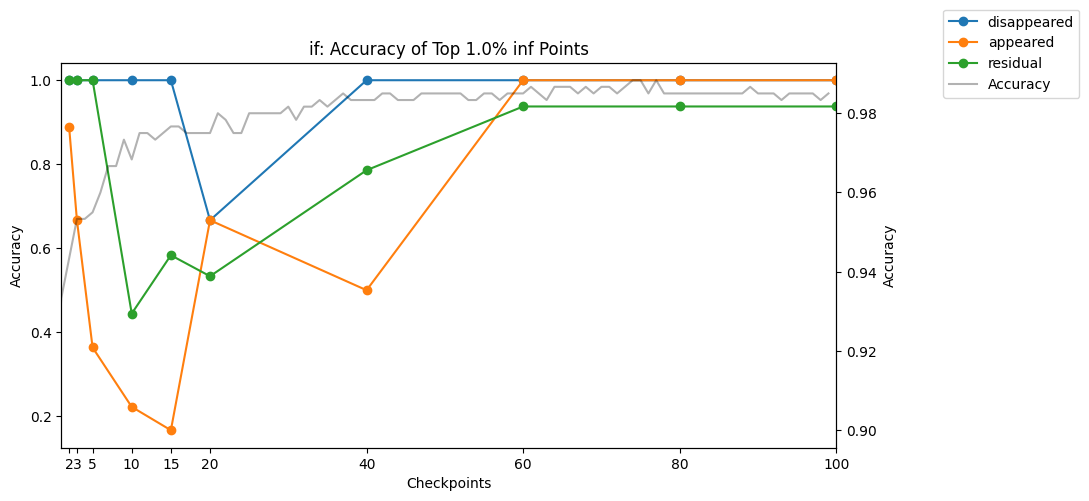

In [157]:
topinf_indexes = top_inf_indices(dogfish_influence_if, int(p*num_data))
def compute_accuracy(model, dataset):
    outputs = torch.tensor([model(torch.tensor(data[0]).unsqueeze(0)) for data in dataset])
    predictions = (outputs > 0.5).int()
    expect_val = torch.tensor([data[1] for data in dataset], device=device)
    accuracy = (predictions == expect_val).sum() / len(expect_val)
    return accuracy

disappeared_accuracies = []
appeared_accuracies = []
residual_accuracies = []

for i in range(1, len(topinf_indexes)):
    checkpoint = checkpoints_filepaths[i]
    optimizer = torch.optim.Adam(V3FC().parameters(), lr=1e-4)
    model, _, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
    
    disappear_topinf_indices = set(topinf_indexes[i-1]).difference(set(topinf_indexes[i]))
    disappear_subset = Subset(embeds_train_dataset, list(disappear_topinf_indices))
    disappear_accuracy = compute_accuracy(model, disappear_subset)
    disappeared_accuracies.append(disappear_accuracy)
    
    newly_appeared_indices = set(topinf_indexes[i]).difference(topinf_indexes[i-1])
    appeared_subset = Subset(embeds_train_dataset, list(newly_appeared_indices))
    appeared_accuracy = compute_accuracy(model, appeared_subset)
    appeared_accuracies.append(appeared_accuracy)
    
    residual_indices = set(topinf_indexes[i]).intersection(topinf_indexes[i-1])
    residual_subset = Subset(embeds_train_dataset, list(residual_indices))
    residual_accuracy = compute_accuracy(model, residual_subset)
    residual_accuracies.append(residual_accuracy)

kwargs = {
    "data": [disappeared_accuracies, appeared_accuracies, residual_accuracies],
    "title": f"if: Accuracy of Top {p*100}% inf Points",
    "y_label": "Accuracy",
    "legend_labels": ["disappeared", "appeared", "residual"]
}

plot_var_acc_legends(x_vals, checkpoint_labels[1:], accuracies, **kwargs)


Plotting Decision Boundary: 100%|██████████| 11/11 [00:00<00:00, 11.62it/s]


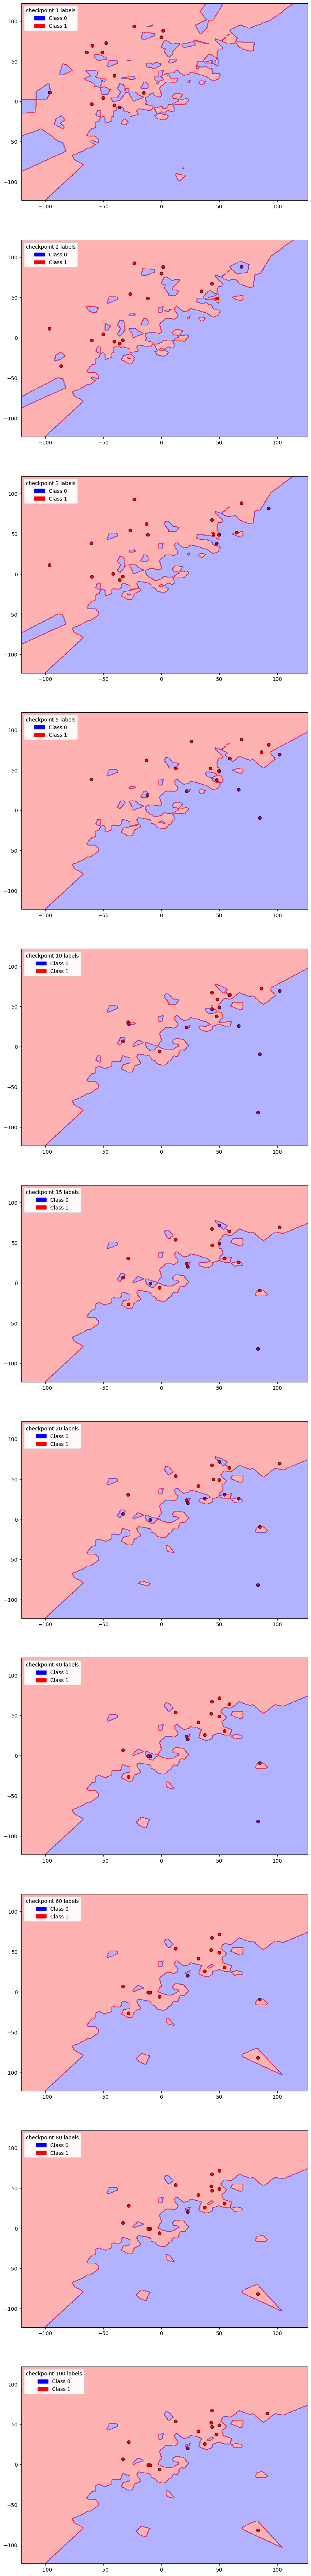

In [145]:
p = 0.01
ckpts_top_inf_indices = top_inf_indices(dogfish_influence_if, int(p*num_data))
for i in range(len(scoring_methods)):
    all_x_2d, all_data_y, all_data_x = tsne_all_dataset(embeds_train_dataset)
    fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
    custom_cmap = mcolors.ListedColormap(["blue", "red"])
    norm = mcolors.Normalize(0, 1)
    unique_labels = np.unique(all_data_y)
    for i, ckpt_top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
        model, _, _, _ = load_checkpoint(V3FC().to(device), torch.optim.Adam(V3FC().parameters(), lr=0.0001), checkpoints_filepaths[i])
        all_y_pred = (model(torch.tensor(all_data_x, dtype=torch.float32, device=device)) > 0.5).int().detach().numpy().flatten()
        plt_decision_boundary(ckpt_top_inf_indices, checkpoint_labels, all_x_2d, all_data_y, all_y_pred, ax[i], i, custom_cmap, norm, unique_labels)
    # fig.tight_layout()
    plt.show()

In [131]:
def train_without_topinf(influences, train_dataset, test_loader, checkpoints_filepaths):
    ckpts_top_inf_indices = top_inf_indices(influences, int(p*num_data))
    optimizer = torch.optim.Adam(V3FC().parameters(), lr=1e-4)
    model_tmp, optimizer_tmp, _, _ = load_checkpoint(V3FC(), optimizer, checkpoints_filepaths[0])
    modified_models = [{
        "model": model_tmp,
        "optimizer": optimizer_tmp,
    }]
    subsets = []
    for i in range(len(checkpoints_filepaths) - 1):
        top_indexes = ckpts_top_inf_indices[i]
        filtered_indices = [i for i in list(range(len(train_dataset))) if i not in top_indexes]
        residual_train_dataset = Subset(train_dataset, filtered_indices)
        residual_dataloader = DataLoader(residual_train_dataset, batch_size=64, shuffle=True)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoints_filepaths[i])
        criterion = nn.BCELoss()
        epochs = checkpoint_labels[i+1] - checkpoint_labels[i]
        
        ckpt_filepath, _ = train_func_classification(
            model, criterion, optimizer, residual_dataloader, test_loader, epochs, lambda pred: (pred > 0.5).int(), device, dir_ckpt="../checkpoint/V3FC_tmp", save=True, record_checkpoints=[epochs])
        
        model_tmp, optimizer_tmp, _, _ = load_checkpoint(model, optimizer, ckpt_filepath[0])
        modified_models.append({
            "model": model_tmp,
            "optimizer": optimizer_tmp,
        })
        subsets.append(residual_train_dataset)
    return modified_models, subsets

modified_models, _ = train_without_topinf(dogfish_influence_if, embeds_train_dataset, test_loader, checkpoints_filepaths)

Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_1_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_1_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_2_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_5_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_5_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_5_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_20_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_20_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_20_1.0.pth
Checkpoint at 1.0 saved: ../checkpoint/V3FC_tmp\V3FC_epoch_20_1.0.pth


Plotting Decision Boundary: 100%|██████████| 11/11 [00:01<00:00,  9.37it/s]


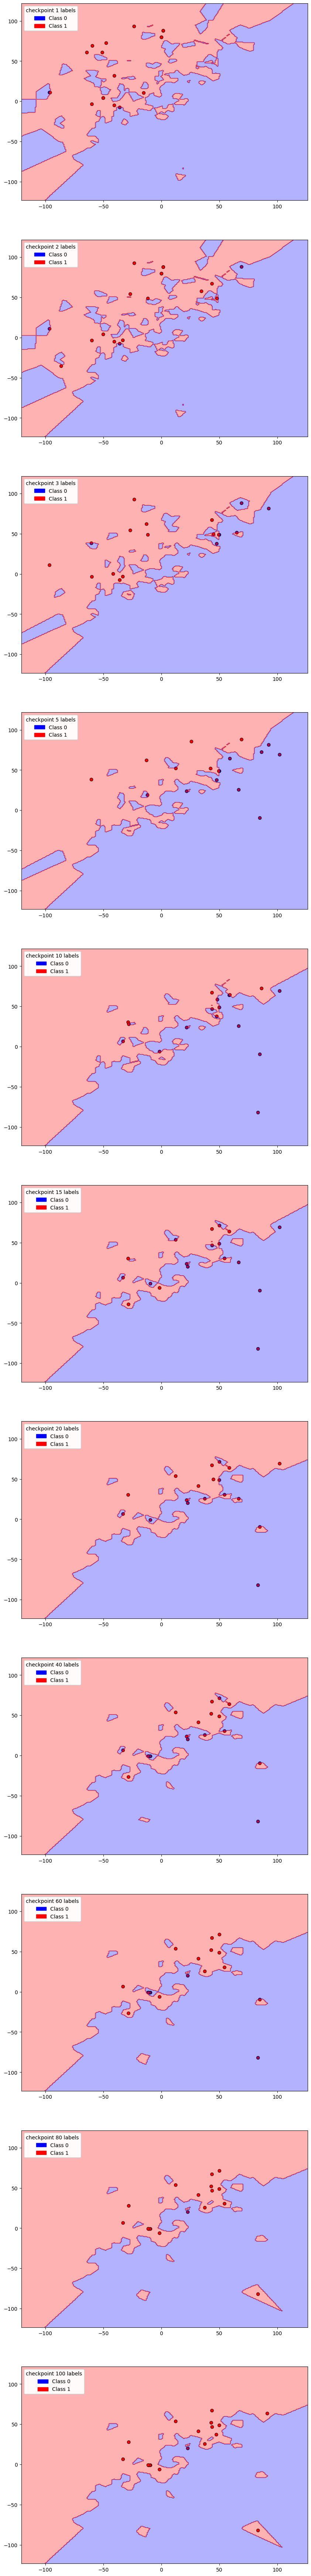

In [163]:
ckpts_top_inf_indices = top_inf_indices(dogfish_influence_if, int(p*num_data))
all_x_2d, all_data_y, all_data_x = tsne_all_dataset(embeds_train_dataset)
fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
custom_cmap = mcolors.ListedColormap(["blue", "red"])
norm = mcolors.Normalize(0, 1)
unique_labels = np.unique(all_data_y)

for i, ckpt_top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
    # model: trained from removed 
    model = modified_models[i]["model"]
    optimizer = modified_models[i]["optimizer"]
    all_y_pred = (model(torch.tensor(all_data_x, dtype=torch.float32, device=device)) > 0.5).int().detach().numpy().flatten()
    plt_decision_boundary(ckpt_top_inf_indices, checkpoint_labels, all_x_2d, all_data_y, all_y_pred, ax[i], i, custom_cmap, norm, unique_labels=unique_labels)
# fig.tight_layout()
plt.show()